# Ablation

In [1]:
from pathlib import Path
import os
import sys
import subprocess

repo_dir = Path("/kaggle/working/eX-LAViTs")
if not repo_dir.exists():
    subprocess.run(
        ["git", "clone", "https://github.com/VuTrinhNguyenHoang/eX-LAViTs.git", str(repo_dir)],
        check=True,
    )
os.chdir(repo_dir)
sys.path.insert(0, str(repo_dir))
print("Code:", subprocess.check_output(["git", "rev-parse", "HEAD"], text=True).strip())


Cloning into '/kaggle/working/eX-LAViTs'...


Code: 742dd02bcc0f05d1fb5985bd6362aafd52f1c476


In [2]:
%pip install -q timm==1.0.30 scikit-learn psutil soundfile pyarrow==19.0.1 medmnist matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 33.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.1/42.1 MB 50.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 5.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.48.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
datasets 4.8.5 requires pyarrow>=21.0.0, but you have pyarrow 19.0.1 which is incompatible.
bigframes 2.48.0 requires pyarrow>=23.0.1, but you have pyarrow 19.0.1 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


In [3]:
from dataclasses import asdict
import json
import hashlib
import importlib.metadata
import time
import numpy as np
import pandas as pd
import torch
import torchvision.transforms as T
import torchaudio
import soundfile as sf
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import Dataset
from sklearn.model_selection import train_test_split
from IPython.display import display
import medmnist
from medmnist import INFO
from datasets.stl10 import get_stl10_dataloaders
from datasets.cifar10 import get_cifar10_dataloaders
from src.models.linear_vit import create_linear_attention_vit
from src.models.linear_text_transformer import LinearTextTransformer
from src.models.explainability.linear_rollout import LAGRA, TextLAGRA, LAGRAConfig
from src.utils.speech_preprocessing import Speech2Image, Speech2ImageConfig
from src.utils.revision_evaluation import (
    evaluate_methods,
    method_factories,
    benchmark_methods,
    save_metadata,
    format_summary,
)

## Configuration

In [4]:
model_dir = Path("/kaggle/input/models/trnhvu/lagra/pytorch/default/2")
DATASETS = [
    "dogcat", "animal", "stl10", "cifar10", "medmnist",
    "agnews", "imdb", "movie-reviews", "esc50", "speechcommands",
]
data_dirs = {
    "dogcat": Path("/kaggle/input/datasets/ashfakyeafi/cat-dog-images-for-classification"),
    "animal": Path("/kaggle/input/datasets/alessiocorrado99/animals10"),
    "stl10": Path("/kaggle/input/datasets/pratt3000/stl10-binary-files"),
    "cifar10": Path("/kaggle/working/data"),
    "medmnist": Path("/kaggle/working/data"),
    "agnews": Path("/kaggle/input/datasets/trnhvu/ex-la-text"),
    "imdb": Path("/kaggle/input/datasets/trnhvu/ex-la-text"),
    "movie-reviews": Path("/kaggle/input/datasets/trnhvu/ex-la-text"),
    "esc50": Path("/kaggle/input/datasets/trnhvu/esc-50/ESC-50-master"),
    "speechcommands": Path("/kaggle/input/datasets/yashdogra/speech-commands"),
}
legacy_stl10_dir = Path("/kaggle/input/stl10-binary-files")
if not data_dirs["stl10"].is_dir() and legacy_stl10_dir.is_dir():
    data_dirs["stl10"] = legacy_stl10_dir
MAX_SAMPLES = {
    "dogcat": None, "animal": 640, "stl10": 640, "cifar10": 640,
    "medmnist": 1080, "agnews": 200, "imdb": 200,
    "movie-reviews": 100, "esc50": None, "speechcommands": 500,
}
modalities = {
    **dict.fromkeys(["dogcat", "animal", "stl10", "cifar10", "medmnist"], "Image"),
    **dict.fromkeys(["agnews", "imdb", "movie-reviews"], "Text"),
    **dict.fromkeys(["esc50", "speechcommands"], "Audio"),
}
text_files = {
    "agnews": "ag_news_subset.parquet",
    "imdb": "imdb_reviews.parquet",
    "movie-reviews": "movie_rationales.parquet",
}
STEPS = 20
SEED = 42
PAD_ID = 0
NUM_WORKERS = 0
output_root = Path("/kaggle/working/ablation_nonorm")
output_root.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
variants = {
    "LAGRA (full)": LAGRAConfig(normalize="none"),
    "NoGrad": LAGRAConfig(normalize="none", use_grad=False),
    "NoReLU": LAGRAConfig(normalize="none", use_relu=False),
    "NoRes": LAGRAConfig(normalize="none", use_residual=False),
    "NoRoll": LAGRAConfig(normalize="none", rollout=False),
    "SingleNorm": LAGRAConfig(normalize="single"),
    "WithNorm": LAGRAConfig(normalize="double"),
}
RESUME = True
for name in DATASETS:
    checkpoint_path = model_dir / f"{name}.pth"
    if not checkpoint_path.is_file():
        raise FileNotFoundError(checkpoint_path)
    if name not in ("cifar10", "medmnist") and not data_dirs[name].is_dir():
        raise FileNotFoundError(data_dirs[name])
    if name in text_files and not (data_dirs[name] / text_files[name]).is_file():
        raise FileNotFoundError(data_dirs[name] / text_files[name])
print("Device:", DEVICE, "GPU:", torch.cuda.get_device_name() if DEVICE.type == "cuda" else None)
print("Variants:", {name: asdict(config) for name, config in variants.items()})
display(pd.DataFrame({"dataset": DATASETS, "max_samples": [MAX_SAMPLES[name] for name in DATASETS]}))
print("Output:", output_root)

Device: cuda GPU: Tesla T4
Variants: {'LAGRA (full)': {'use_grad': True, 'use_relu': True, 'use_residual': True, 'normalize': 'none', 'rollout': True}, 'NoGrad': {'use_grad': False, 'use_relu': True, 'use_residual': True, 'normalize': 'none', 'rollout': True}, 'NoReLU': {'use_grad': True, 'use_relu': False, 'use_residual': True, 'normalize': 'none', 'rollout': True}, 'NoRes': {'use_grad': True, 'use_relu': True, 'use_residual': False, 'normalize': 'none', 'rollout': True}, 'NoRoll': {'use_grad': True, 'use_relu': True, 'use_residual': True, 'normalize': 'none', 'rollout': False}, 'SingleNorm': {'use_grad': True, 'use_relu': True, 'use_residual': True, 'normalize': 'single', 'rollout': True}, 'WithNorm': {'use_grad': True, 'use_relu': True, 'use_residual': True, 'normalize': 'double', 'rollout': True}}


,dataset,max_samples
0,dogcat,NaN
1,animal,640.0
2,stl10,640.0
3,cifar10,640.0
4,medmnist,1080.0
5,agnews,200.0
6,imdb,200.0
7,movie-reviews,100.0
8,esc50,NaN
9,speechcommands,500.0


Output: /kaggle/working/ablation_nonorm


## Data

In [5]:
image_transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
])
audio_transform = T.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))


class ImageDataset(Dataset):
    def __init__(self, frame):
        self.df = frame.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        with Image.open(row["image"]) as image:
            x = image_transform(image.convert("RGB"))
        return x, int(row["labels"])


class TextDataset(Dataset):
    def __init__(self, frame):
        self.df = frame.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        ids = np.array(row["input_ids"], dtype=np.int64)
        rationale = np.array(row["rationale_mask"], dtype=np.int64) if "rationale_mask" in self.df else np.zeros_like(ids)
        return {
            "input_ids": torch.from_numpy(ids),
            "label": torch.tensor(int(row["label"]), dtype=torch.long),
            "rationale_mask": torch.from_numpy(rationale),
        }


class AudioDataset(Dataset):
    def __init__(self, frame, window_sec):
        self.df = frame.reset_index(drop=True)
        self.s2i = Speech2Image(Speech2ImageConfig(
            sample_rate=16000, window_sec=window_sec, n_fft=512,
            win_length=400, hop_length=160, n_mels=224,
            fmin=20.0, fmax=7600.0, out_hw=224,
        ))

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        waveform, sr = sf.read(row["path"], dtype="float32", always_2d=True)
        wav = torch.from_numpy(waveform.T.copy())
        wav = wav.mean(dim=0) if wav.size(0) > 1 else wav.squeeze(0)
        if sr != 16000:
            wav = torchaudio.functional.resample(wav, sr, 16000)
        return audio_transform(self.s2i(wav)), torch.tensor(int(row["label_idx"])).long()

In [6]:
def load_test_dataset(name):
    data_dir = data_dirs[name]
    if name in ("stl10", "cifar10"):
        size = 96 if name == "stl10" else 32
        load = get_stl10_dataloaders if name == "stl10" else get_cifar10_dataloaders
        _, _, loader = load(
            data_dir=str(data_dir), img_size=size, batch_size=64,
            num_workers=NUM_WORKERS, download=name != "stl10",
        )
        dataset = loader.dataset
        manifest = pd.DataFrame({"sample_id": np.arange(len(dataset))})
        return dataset, size, 10, manifest, "original torchvision test split"

    if name == "medmnist":
        info = INFO["pathmnist"]
        data_dir.mkdir(parents=True, exist_ok=True)
        dataset = getattr(medmnist, info["python_class"])(
            split="test", root=str(data_dir), transform=image_transform, download=True,
        )
        manifest = pd.DataFrame({"sample_id": np.arange(len(dataset))})
        return dataset, 224, len(info["label"]), manifest, "original PathMNIST native test split"

    if name in text_files:
        frame = pd.read_parquet(data_dir / text_files[name])
        n_classes = frame["label"].nunique()
        frame["source_index"] = np.arange(len(frame))
        frame = frame[frame["split"] == "test"].reset_index(drop=True)
        ratio = {"agnews": 0.5, "imdb": 0.15, "movie-reviews": 1.0}[name]
        if ratio < 1.0:
            frame = frame.sample(frac=ratio, random_state=SEED).reset_index(drop=True)
        dataset = TextDataset(frame)
        manifest = pd.DataFrame({
            "sample_id": [f"test:{index}" for index in range(len(dataset))],
            "source_index": frame["source_index"], "label": frame["label"],
        })
        protocol = f"original Parquet test split; subset_ratio={ratio}; seed 42; encoded inputs retained unchanged"
        return dataset, None, n_classes, manifest, protocol

    if name == "esc50":
        frame = pd.read_csv(data_dir / "meta" / "esc50.csv")
        n_classes = frame["target"].nunique()
        frame["path"] = frame["filename"].map(lambda value: str(data_dir / "audio" / value))
        frame["label_idx"] = frame["target"].astype(int)
        frame = frame[frame["fold"] == 1].copy().reset_index(drop=True)
        dataset = AudioDataset(frame, window_sec=5.0)
        manifest = dataset.df.rename(columns={"path": "sample_id"}).copy()
        return dataset, 224, n_classes, manifest, "original ESC50 test fold 1; CSV order"

    if name == "speechcommands":
        classes = ["yes", "no", "up", "down", "left", "right", "stop", "go"]
        records = []
        for label in classes:
            for wav_file in (data_dir / label).glob("*.wav"):
                records.append({"path": str(wav_file), "label": label})
        frame = pd.DataFrame(records)
        label_to_id = {label: index for index, label in enumerate(sorted(classes))}
        frame["label_idx"] = frame["label"].map(label_to_id)
        frame = frame.sample(frac=1.0, random_state=SEED).reset_index(drop=True)
        test_rows = []
        for label, group in frame.groupby("label"):
            n_train, n_valid = int(len(group) * 0.8), int(len(group) * 0.1)
            test_rows.append(group.iloc[n_train + n_valid:])
        frame = pd.concat(test_rows).sample(frac=1.0, random_state=SEED).reset_index(drop=True)
        dataset = AudioDataset(frame, window_sec=2.24)
        manifest = dataset.df.rename(columns={"path": "sample_id"}).copy()
        protocol = "original class-wise 80/10/10; seed 42; glob order retained"
        return dataset, 224, len(classes), manifest, protocol

    if name == "dogcat":
        frame = pd.read_csv(data_dir / "cat_dog.csv")
        frame["image"] = frame["image"].map(lambda value: str(data_dir / "cat_dog" / value))
        protocol = "original stratified 70/15/15; seed 42; CSV order"
    elif name == "animal":
        translate = {
            "cane": "dog", "cavallo": "horse", "elefante": "elephant",
            "farfalla": "butterfly", "gallina": "chicken", "gatto": "cat",
            "mucca": "cow", "pecora": "sheep", "ragno": "spider", "scoiattolo": "squirrel",
        }
        rows = []
        for label in os.listdir(data_dir / "raw-img"):
            directory = data_dir / "raw-img" / label
            if directory.is_dir():
                for filename in os.listdir(directory):
                    rows.append({"image": str(directory / filename), "labels": translate.get(label, label)})
        frame = pd.DataFrame(rows)
        label_to_id = {label: index for index, label in enumerate(sorted(frame["labels"].unique()))}
        frame["labels"] = frame["labels"].map(label_to_id)
        protocol = "original stratified 70/15/15; seed 42; os.listdir order retained; historical file order cannot be independently verified"
    else:
        raise ValueError(f"Unsupported dataset: {name}")
    _, remaining = train_test_split(frame, test_size=0.3, random_state=SEED, stratify=frame["labels"])
    _, test_frame = train_test_split(remaining, test_size=0.5, random_state=SEED, stratify=remaining["labels"])
    dataset = ImageDataset(test_frame)
    manifest = dataset.df.rename(columns={"image": "sample_id"}).copy()
    return dataset, 224, frame["labels"].nunique(), manifest, protocol

## Evaluation

In [7]:
def load_model(name, image_size, n_classes):
    checkpoint = torch.load(model_dir / f"{name}.pth", map_location="cpu", weights_only=False)
    state = checkpoint["model_state_dict"] if "model_state_dict" in checkpoint else checkpoint
    if modalities[name] == "Text":
        model = LinearTextTransformer(
            vocab_size=state["token_embed.weight"].shape[0],
            num_classes=int(n_classes), max_seq_len=512,
            embed_dim=768, depth=4, num_heads=8, mlp_ratio=4.0,
            drop_rate=0.2, attn_drop_rate=0.0,
            drop_path_rate=0.2, mlp_drop_rate=0.1, kernel="elu", eps=1e-6,
        )
        model.token_embed.weight.requires_grad_(False)
    else:
        model = create_linear_attention_vit(
            "vit_tiny_patch16_224", pretrained=False,
            num_classes=int(n_classes), img_size=image_size, verbose=False,
        )
    model.load_state_dict(state, strict=True)
    return model.to(DEVICE).eval()

In [8]:
summary_frames, compute_frames = [], []
method_settings = {name: asdict(settings) for name, settings in variants.items()}
source_digest = hashlib.sha256()
for filename in (
    "src/models/transformer.py", "src/models/linear_vit.py",
    "src/models/linear_text_transformer.py", "src/models/explainability/linear_rollout.py",
    "src/utils/metrics.py", "src/utils/revision_evaluation.py",
    "src/utils/speech_preprocessing.py",
    "src/models/explainability/attention_baselines.py",
    "src/models/explainability/gradcam.py",
    "src/models/explainability/integrated_gradient.py",
    "src/models/explainability/rollout.py",
    "datasets/cifar10.py", "datasets/stl10.py",
):
    source_digest.update(filename.encode())
    source_digest.update(Path(filename).read_bytes())
source_sha256 = source_digest.hexdigest()

for name in DATASETS:
    started = time.perf_counter()
    print(f"\nDataset: {name}", flush=True)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    dataset, image_size, n_classes, manifest, split_protocol = load_test_dataset(name)
    limit = MAX_SAMPLES[name]
    count = len(dataset) if limit is None else min(limit, len(dataset))
    selected_manifest = manifest.iloc[:count]
    output_dir = output_root / name
    output_dir.mkdir(parents=True, exist_ok=True)
    checkpoint_path = model_dir / f"{name}.pth"
    with checkpoint_path.open("rb") as handle:
        checkpoint_sha256 = hashlib.file_digest(handle, "sha256").hexdigest()
    text = modalities[name] == "Text"
    config = dict(
        protocol_version="lagra_nonorm_ablation_v1",
        dataset=name, modality=modalities[name], seed=SEED,
        max_samples=limit, evaluated_samples=count, steps=STEPS,
        model_name="LinearTextTransformer" if text else "vit_tiny_patch16_224",
        image_size=image_size, max_length=512 if text else None,
        kernel="elu", eps=1e-6, data_dir=str(data_dirs[name]),
        split_protocol=split_protocol,
        sample_selection="first test examples in original notebook order; shared across variants",
        rollout_order="A_tilde_1...A_tilde_L; CLS row-vector multiplication",
        single_norm_position="before adding the residual identity",
        double_norm_position="before and after adding the residual identity",
        no_rollout="last block only; no row normalization",
        final_map_normalization="shared nonnegative maximum normalization",
        pad_id=PAD_ID if text else None,
        validation_test_overlap=name in ("agnews", "imdb"),
        source_sha256=source_sha256,
        manifest_sha256=hashlib.sha256(selected_manifest.to_csv(index=False).encode()).hexdigest(),
        checkpoint_sha256=checkpoint_sha256,
        variants=method_settings,
        gpu=torch.cuda.get_device_name() if DEVICE.type == "cuda" else None,
        compute_warmup=3, compute_repeats=10, compute_batch_size=1,
        compute_methods=["Forward", "GradCAM", "IG", "Rollout", "GradientRollout", "CDAM", "GMAR", *variants],
    )
    if text:
        config["model_config"] = dict(
            embed_dim=768, depth=4, num_heads=8, mlp_ratio=4.0,
            drop_rate=0.2, attn_drop_rate=0.0, drop_path_rate=0.2, mlp_drop_rate=0.1,
        )
        config["pyarrow_version"] = importlib.metadata.version("pyarrow")
        config["input_encoding"] = "existing BERT token IDs retained; checkpoint includes token and position embeddings"
    else:
        config["normalization_mean"] = [0.485, 0.456, 0.406]
        config["normalization_std"] = [0.229, 0.224, 0.225]
    if modalities[name] == "Audio":
        config["frontend"] = asdict(dataset.s2i.cfg)
        config["audio_versions"] = {package: importlib.metadata.version(package) for package in ("torchaudio", "soundfile")}
    signature = hashlib.sha256(json.dumps(config, sort_keys=True).encode()).hexdigest()
    config["run_signature"] = signature
    summary_path = output_dir / "summary.csv"
    metadata_path = output_dir / "metadata.json"
    compute_path = output_dir / "compute.csv"
    reuse = RESUME and summary_path.is_file()
    if reuse:
        if not metadata_path.is_file():
            raise ValueError(f"Missing metadata for saved results: {output_dir}")
        previous_metadata = json.loads(metadata_path.read_text())
        if previous_metadata["config"].get("run_signature") != signature:
            raise ValueError(f"Saved results use different inputs, code, or settings: {output_dir}. Choose a new output_root.")
        summary = pd.read_csv(summary_path, index_col="method")
        if set(summary.index) != set(variants) or not summary["n_samples"].eq(count).all():
            raise ValueError(f"Incomplete saved variant results: {summary_path}")
        summary = summary.loc[list(variants)]
        print(f"Reused matching results: {name}", flush=True)
    print(f"Test: {len(dataset)} | Evaluate: {count} | Variants: {len(variants)}", flush=True)
    print("Loading:", checkpoint_path, flush=True)
    model = load_model(name, image_size, n_classes)
    explainer_cls = TextLAGRA if text else LAGRA
    factories = {
        label: lambda settings=settings: explainer_cls(model, config=settings)
        for label, settings in variants.items()
    }
    compute_factories = method_factories(model, text=text)
    compute_factories.pop("Ours")
    compute_factories.update(factories)
    if not reuse:
        selected_manifest.to_csv(output_dir / "test_manifest.csv", index=False)
        save_metadata(output_dir, config, model, checkpoint_path, method_details=method_settings)
        summary = evaluate_methods(
            model, dataset, DEVICE, output_dir, max_samples=limit, steps=STEPS,
            pad_id=PAD_ID if text else None,
            sample_ids=manifest["sample_id"].tolist(), factories=factories,
        )
    display(format_summary(summary))
    summary = summary.copy()
    summary["source"] = "matched nonorm ablation; shared checkpoint and samples"
    summary_frames.append(summary.reset_index().assign(dataset=name, modality=modalities[name]))
    pd.concat(summary_frames, ignore_index=True).to_csv(output_root / "summary.csv", index=False)

    sample = dataset[0]
    xb = (sample["input_ids"] if text else sample[0]).unsqueeze(0).to(DEVICE)
    if reuse and compute_path.is_file():
        compute = pd.read_csv(compute_path, index_col="method")
        if set(compute.index) != {"Forward", *compute_factories}:
            raise ValueError(f"Incomplete saved compute results: {compute_path}")
    else:
        compute = benchmark_methods(model, xb, output_dir, text=text, factories=compute_factories)
    compute = compute.copy()
    compute["source"] = "matched nonorm ablation; shared checkpoint and input"
    compute_frames.append(compute.reset_index().assign(dataset=name, modality=modalities[name]))
    pd.concat(compute_frames, ignore_index=True).to_csv(output_root / "compute.csv", index=False)
    print(f"Saved: {output_dir} | {(time.perf_counter() - started) / 60:.1f} min", flush=True)
    del model, dataset, xb, sample, factories, compute_factories
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()


Dataset: dogcat
Test: 3750 | Evaluate: 3750 | Variants: 7
Loading: /kaggle/input/models/trnhvu/lagra/pytorch/default/2/dogcat.pth


Evaluation:   0%|          | 5/3750 [00:20<4:16:12,  4.10s/it]

Evaluated 10/3750 samples; 0.7 min


Evaluation:   0%|          | 17/3750 [01:08<4:06:06,  3.96s/it]

Evaluated 20/3750 samples; 1.3 min


...

Evaluation: 100%|█████████▉| 498/500 [29:43<00:07,  3.56s/it]

Evaluated 500/500 samples; 29.9 min


Evaluation: 100%|██████████| 500/500 [29:51<00:00,  3.58s/it]


,auc_del,auc_ins,entropy,gini,cosine_cs,n_samples
method,,,,,,
LAGRA (full),0.1728 ± 0.1249,0.4137 ± 0.1873,0.7243 ± 0.0936,0.9458 ± 0.0517,0.7583 ± 0.1595,500
NoGrad,0.1871 ± 0.1256,0.3930 ± 0.1852,0.7434 ± 0.0521,0.9640 ± 0.0187,1.0000 ± 0.0000,500
NoReLU,0.2510 ± 0.2037,0.2878 ± 0.1821,0.5740 ± 0.1882,0.8630 ± 0.1423,0.3821 ± 0.2687,500
NoRes,0.1995 ± 0.1286,0.4033 ± 0.1859,0.6066 ± 0.1650,0.8812 ± 0.1649,0.0000 ± 0.0000,500
NoRoll,0.1995 ± 0.1286,0.4033 ± 0.1859,0.6066 ± 0.1650,0.8812 ± 0.1649,0.7186 ± 0.2189,500
SingleNorm,0.1776 ± 0.1296,0.3954 ± 0.1851,0.7429 ± 0.0597,0.9570 ± 0.0232,0.8308 ± 0.1152,500
WithNorm,0.1775 ± 0.1289,0.3905 ± 0.1856,0.7615 ± 0.0659,0.9588 ± 0.0233,0.8258 ± 0.1168,500


Forward: 8.76 ± 0.23 ms
GradCAM: 26.18 ± 0.44 ms
IG: 884.65 ± 26.89 ms
Rollout: 11.46 ± 0.22 ms
GradientRollout: 31.14 ± 1.07 ms
CDAM: 29.47 ± 1.22 ms
GMAR: 34.05 ± 1.22 ms
LAGRA (full): 30.57 ± 0.93 ms
NoGrad: 30.43 ± 1.44 ms
NoReLU: 30.85 ± 5.39 ms
NoRes: 28.15 ± 0.45 ms
NoRoll: 28.53 ± 0.79 ms
SingleNorm: 29.44 ± 0.40 ms
WithNorm: 30.94 ± 1.26 ms
Saved: /kaggle/working/ablation_nonorm/speechcommands | 30.2 min


## Results

In [9]:
metrics = ["auc_del", "auc_ins", "entropy", "cosine_cs"]
combined = pd.concat(summary_frames, ignore_index=True)
if combined.duplicated(["dataset", "method"]).any():
    raise ValueError("Duplicate dataset-method summaries; rerun the Evaluation cell before aggregating.")
completed_datasets = [
    name for name in DATASETS
    if set(combined.loc[combined["dataset"] == name, "method"]) == set(variants)
]
if not completed_datasets:
    raise ValueError("No dataset has results for every variant.")
combined = combined[combined["dataset"].isin(completed_datasets)].copy()
means = combined[["dataset", "modality", "method", "source", *[metric + "_mean" for metric in metrics]]].copy()
means = means.rename(columns={metric + "_mean": metric for metric in metrics})
means.to_csv(output_root / "dataset_means.csv", index=False)
method_order = list(variants)

ablation_results = means.groupby("method", sort=False)[metrics].agg(["mean", "std", "count"]).reindex(method_order)
ablation_results.columns = [f"{metric}_{'n_datasets' if statistic == 'count' else statistic}" for metric, statistic in ablation_results.columns]
ablation_results.to_csv(output_root / "ablation_results.csv")
ablation_formatted = pd.DataFrame(index=ablation_results.index)
for metric in metrics:
    ablation_formatted[metric] = [
        f"{mean:.4f} ± {std:.4f}"
        for mean, std in zip(ablation_results[metric + "_mean"], ablation_results[metric + "_std"])
    ]
ablation_formatted["n_datasets"] = ablation_results["auc_del_n_datasets"]
ablation_formatted.to_csv(output_root / "ablation_results_formatted.csv")

by_modality = means.groupby(["method", "modality"], sort=False)[metrics].agg(["mean", "std", "count"])
by_modality.columns = [f"{metric}_{'n_datasets' if statistic == 'count' else statistic}" for metric, statistic in by_modality.columns]
by_modality.to_csv(output_root / "modality_summary.csv")
aggregation = {
    "datasets": completed_datasets,
    "requested_datasets": DATASETS,
    "weighting": "equal weight per dataset, including when dataset sample counts differ",
    "std": "sample standard deviation across dataset-level means, ddof=1; not per-example SD",
    "variants": method_settings,
    "source_sha256": source_sha256,
    "comparability": "all variants evaluated together on the same checkpoint and sample cohort; no legacy reference injection",
}
(output_root / "aggregation.json").write_text(json.dumps(aggregation, indent=2))
print("Completed datasets:", completed_datasets)
print("Mean ± SD across dataset means; all variants use matched settings.")
display(ablation_formatted)
display(by_modality)

Completed datasets: ['dogcat', 'animal', 'stl10', 'cifar10', 'medmnist', 'agnews', 'imdb', 'movie-reviews', 'esc50', 'speechcommands']
Mean ± SD across dataset means; all variants use matched settings.


,auc_del,auc_ins,entropy,cosine_cs,n_datasets
method,,,,,
LAGRA (full),0.2572 ± 0.1414,0.7211 ± 0.2136,0.8573 ± 0.1069,0.2194 ± 0.3736,10
NoGrad,0.3906 ± 0.1214,0.6217 ± 0.1700,0.9347 ± 0.0920,1.0000 ± 0.0000,10
NoReLU,0.2983 ± 0.1189,0.6982 ± 0.2421,0.7125 ± 0.1258,0.0136 ± 0.2360,10
NoRes,0.4728 ± 0.2326,0.5612 ± 0.1455,0.8473 ± 0.1675,0.0027 ± 0.0084,10
NoRoll,0.4712 ± 0.2341,0.5621 ± 0.1465,0.8480 ± 0.1651,0.1980 ± 0.3344,10
SingleNorm,0.2711 ± 0.1490,0.7060 ± 0.2125,0.9165 ± 0.0829,0.2203 ± 0.4119,10
WithNorm,0.2753 ± 0.1499,0.7053 ± 0.2134,0.9184 ± 0.0737,0.2095 ± 0.4081,10


,,auc_del_mean,auc_del_std,auc_del_n_datasets,auc_ins_mean,auc_ins_std,auc_ins_n_datasets,entropy_mean,entropy_std,entropy_n_datasets,cosine_cs_mean,cosine_cs_std,cosine_cs_n_datasets
method,modality,,,,,,,,,,,,
LAGRA (full),Image,0.361503,0.099375,5,0.692542,0.123177,5,0.892019,0.079200,5,3.092760e-01,1.975240e-01,5
NoGrad,Image,0.426970,0.083669,5,0.634461,0.100390,5,0.924018,0.077234,5,1.000000e+00,2.915403e-09,5
NoReLU,Image,0.389047,0.068466,5,0.682716,0.123317,5,0.752326,0.106690,5,6.926920e-02,1.664274e-01,5
NoRes,Image,0.380636,0.102197,5,0.666414,0.119457,5,0.787364,0.158768,5,5.301288e-03,1.185404e-02,5
NoRoll,Image,0.377617,0.106156,5,0.667985,0.120809,5,0.788862,0.153903,5,2.639468e-01,1.783949e-01,5
SingleNorm,Image,0.385447,0.098917,5,0.677296,0.112211,5,0.901844,0.060207,5,3.264344e-01,2.673514e-01,5
WithNorm,Image,0.393508,0.089709,5,0.676310,0.111285,5,0.907532,0.052848,5,3.095815e-01,2.506274e-01,5
LAGRA (full),Text,0.110689,0.085057,3,0.962016,0.038848,3,0.814167,0.142583,3,-1.198639e-01,4.600899e-01,3
NoGrad,Text,0.431419,0.143835,3,0.743471,0.202449,3,0.998941,0.000940,3,9.999999e-01,1.538666e-07,3


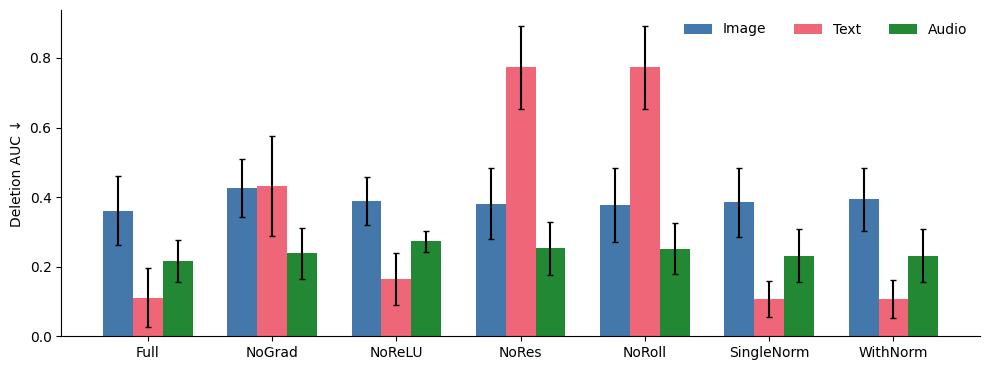

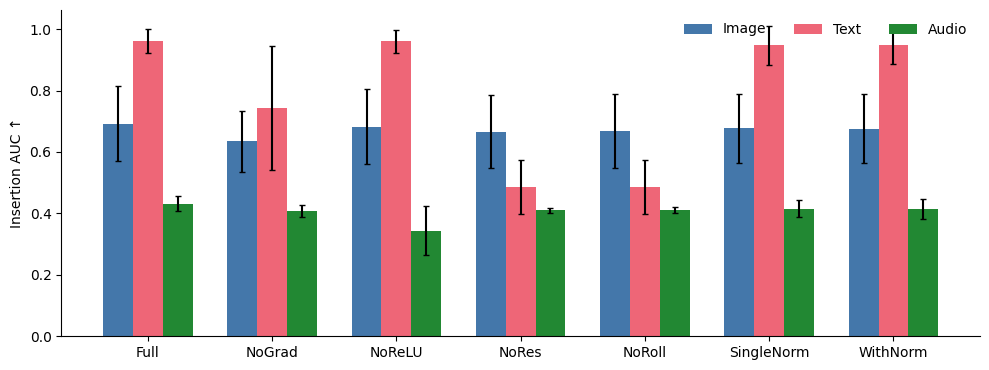

Saved: /kaggle/working/ablation_nonorm


In [10]:
modality_order = [modality for modality in ("Image", "Text", "Audio") if modality in means["modality"].unique()]
colors = {"Image": "#4477AA", "Text": "#EE6677", "Audio": "#228833"}
labels = ["Full", *list(variants)[1:]]
positions = np.arange(len(method_order))
width = 0.24
for metric, ylabel, filename in (
    ("auc_del", "Deletion AUC ↓", "ablation_deletion"),
    ("auc_ins", "Insertion AUC ↑", "ablation_insertion"),
):
    fig, ax = plt.subplots(figsize=(10, 3.8))
    for index, modality in enumerate(modality_order):
        values = by_modality.xs(modality, level="modality").reindex(method_order)
        offset = (index - (len(modality_order) - 1) / 2) * width
        ax.bar(
            positions + offset, values[metric + "_mean"], width,
            yerr=values[metric + "_std"] if values[metric + "_n_datasets"].iloc[0] > 1 else None,
            capsize=2, color=colors[modality], label=modality,
        )
    ax.set_xticks(positions, labels)
    ax.set_ylabel(ylabel)
    ax.legend(frameon=False, ncol=len(modality_order))
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    fig.savefig(output_root / f"{filename}.pdf", bbox_inches="tight")
    fig.savefig(output_root / f"{filename}.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)
print("Saved:", output_root)